# Laboratorio 3: Intuicion estadistica

**Nombre:** Laura Ostos

**C.C:** 1010107809

problema: dos clases con distribución normal bivariante y un clasificador SVC cuyo hiperparámetro $\gamma$ controla la complejidad de la frontera de decisión.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import (train_test_split, KFold, ShuffleSplit, GridSearchCV, learning_curve)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

# muestra n0 puntos de la clase 0 y n1 de la clase 1.
def generar(mu0, cov0, mu1, cov1, n0, n1, seed):
    rng = np.random.default_rng(seed)
    X = np.vstack([rng.multivariate_normal(mu0, cov0, n0),
                   rng.multivariate_normal(mu1, cov1, n1)])
    y = np.r_[np.zeros(n0), np.ones(n1)]
    return X, y

# dibuja la frontera de decision de un clasificador ya entrenado
def frontera(ax, clf, X, y, titulo=""):
    x0, x1 = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    Z = clf.predict(np.c_[x0.ravel(), x1.ravel()]).reshape(x0.shape)
    ax.contourf(x0, x1, Z, cmap="coolwarm", alpha=0.6)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="b", s=12, edgecolor="k", lw=0.3)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="r", s=12, edgecolor="k", lw=0.3)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("X1"); ax.set_ylabel("X2")


Entrenamiento y validación: 480
Test: 120


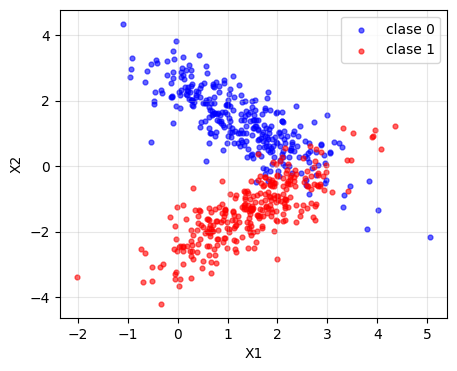

In [3]:
mu0, cov0 = [1.2, 1.4], [[1.0, -0.8], [-0.8, 1.0]]
mu1, cov1 = [1.4, -1.4], [[1.0, 0.8], [0.8, 1.0]]

X, y = generar(mu0, cov0, mu1, cov1, n0=300, n1=300, seed=0)

# se separa el 20% para test y 80% en entrenamiento
X_cv, X_test, y_cv, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
print("Entrenamiento y validación:", len(y_cv))
print("Test:", len(y_test))

plt.figure(figsize=(5, 4))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="b", s=12, alpha=0.6, label="clase 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="r", s=12, alpha=0.6, label="clase 1")
plt.xlabel("X1"); plt.ylabel("X2"); plt.legend(); plt.show()

Mejor gamma (validación cruzada): 1.000  -> score CV = 0.940
Score en TEST con ese gamma:       0.925


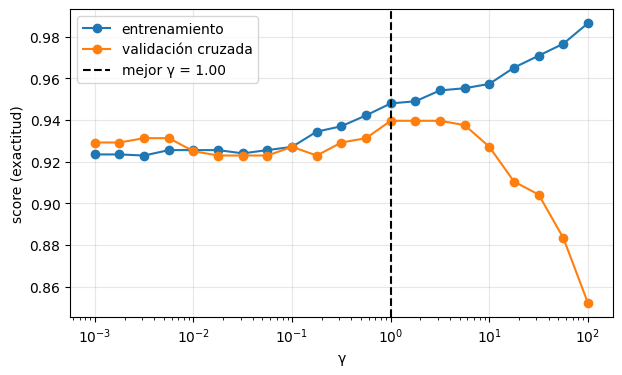

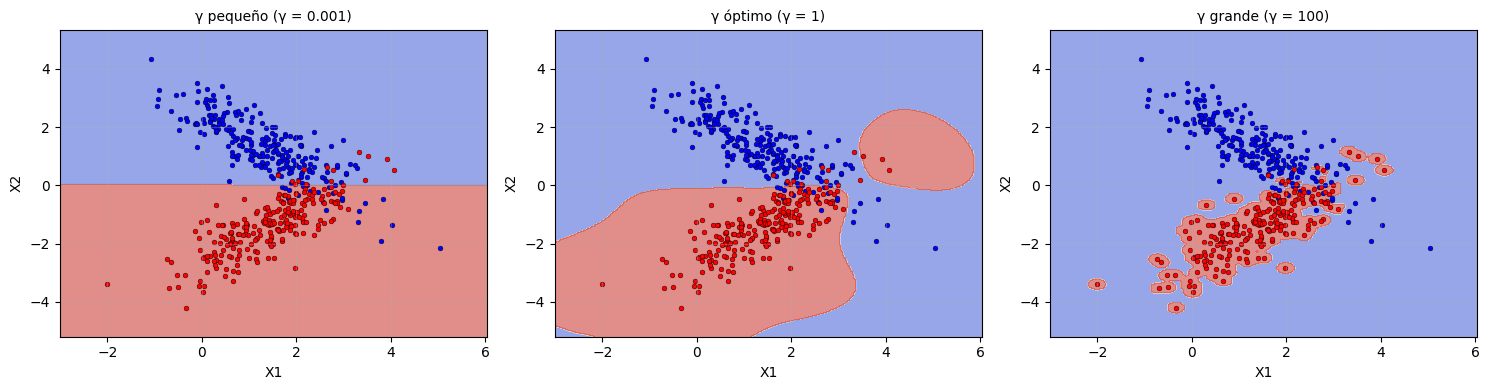

1.Conclusion:
El score de entrenamiento crece siempre con gamma (la frontera se vuelve más flexible y memoriza)
El de validación sube hasta un máximo en gamma aproximado a  0.94 y luego cae con fuerza,  ahí hay overfitting


In [6]:
# 1. construccion curva de score en funcion gamma
gammas = np.logspace(-3, 2, 21)
kf = KFold(n_splits=5, shuffle=True, random_state=0)

score_train, score_val = [], []
for g in gammas:
    tr, va = [], []
    for idx_tr, idx_va in kf.split(X_cv):
        clf = SVC(gamma=g).fit(X_cv[idx_tr], y_cv[idx_tr])
        tr.append(clf.score(X_cv[idx_tr], y_cv[idx_tr]))
        va.append(clf.score(X_cv[idx_va], y_cv[idx_va]))
    score_train.append(np.mean(tr)); score_val.append(np.mean(va))
score_train, score_val = np.array(score_train), np.array(score_val)

g_best = gammas[np.argmax(score_val)]
final = SVC(gamma=g_best).fit(X_cv, y_cv)           # se reentrena con todo el 80 %
print(f"Mejor gamma (validación cruzada): {g_best:.3f}  -> score CV = {score_val.max():.3f}")
print(f"Score en TEST con ese gamma:       {final.score(X_test, y_test):.3f}")

plt.figure(figsize=(7, 4))
plt.semilogx(gammas, score_train, "o-", label="entrenamiento")
plt.semilogx(gammas, score_val, "o-", label="validación cruzada")
plt.axvline(g_best, color="k", ls="--", label=f"mejor γ = {g_best:.2f}")
plt.xlabel("γ"); plt.ylabel("score (exactitud)"); plt.legend(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, g, t in zip(ax, [gammas[0], g_best, gammas[-1]], ["γ pequeño", "γ óptimo", "γ grande"]):
    frontera(a, SVC(gamma=g).fit(X_cv, y_cv), X_cv, y_cv, f"{t} (γ = {g:.3g})")
plt.tight_layout(); plt.show()

print("1.Conclusion:")
print("El score de entrenamiento crece siempre con gamma (la frontera se vuelve más flexible y memoriza)")
print("El de validación sube hasta un máximo en gamma aproximado a  0.94 y luego cae con fuerza,  ahí hay overfitting")

Máx. diferencia manual vs sklearn (train): 0.0
Máx. diferencia manual vs sklearn (valid.): 0.0


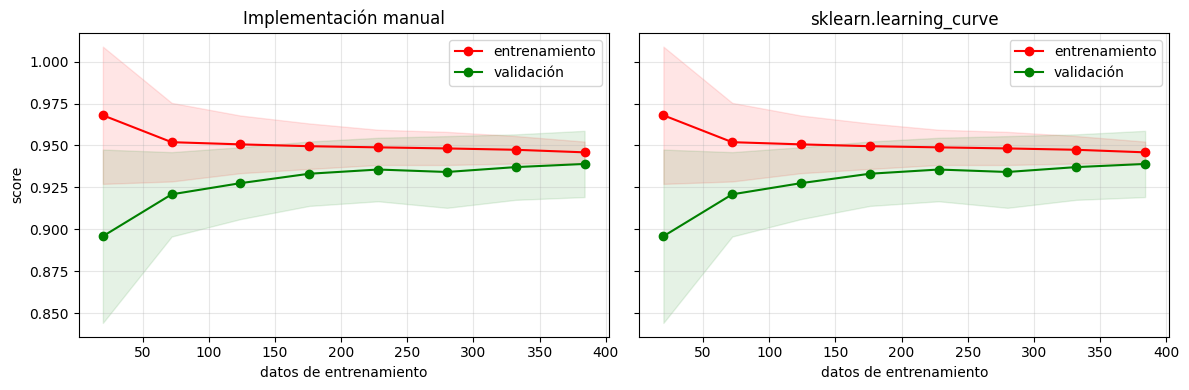

In [7]:
#2. curvas de aprendizaje

def curva_manual(clf, X, y, tamanos, cv):
    tr = np.zeros((len(tamanos), cv.get_n_splits()))
    va = np.zeros_like(tr)
    for j, (idx_tr, idx_va) in enumerate(cv.split(X)):
        for i, s in enumerate(tamanos):
            m = clf.__class__(**clf.get_params()).fit(X[idx_tr[:s]], y[idx_tr[:s]])
            tr[i, j] = m.score(X[idx_tr[:s]], y[idx_tr[:s]])
            va[i, j] = m.score(X[idx_va], y[idx_va])
    return tr, va


clf = SVC(gamma=g_best)
cv = ShuffleSplit(n_splits=50, test_size=0.2, random_state=0)
n_train = len(y_cv) - int(np.ceil(0.2 * len(y_cv)))   # datos de entrenamiento por particion
tamanos = np.linspace(20, n_train, 8).astype(int)

tr_m, va_m = curva_manual(clf, X_cv, y_cv, tamanos, cv)
_, tr_s, va_s = learning_curve(clf, X_cv, y_cv, train_sizes=tamanos, cv=cv)

print("Máx. diferencia manual vs sklearn (train):", np.abs(tr_m - tr_s).max())
print("Máx. diferencia manual vs sklearn (valid.):", np.abs(va_m - va_s).max())

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (tr, va), t in zip(ax, [(tr_m, va_m), (tr_s, va_s)], ["Implementación manual", "sklearn.learning_curve"]):
    a.plot(tamanos, tr.mean(1), "o-", c="r", label="entrenamiento")
    a.fill_between(tamanos, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), color="r", alpha=0.1)
    a.plot(tamanos, va.mean(1), "o-", c="g", label="validación")
    a.fill_between(tamanos, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color="g", alpha=0.1)
    a.set_title(t); a.set_xlabel("datos de entrenamiento"); a.legend()
ax[0].set_ylabel("score")
plt.tight_layout(); plt.show()

GridSearchCV: mejor gamma = 1.000, score CV = 0.940
Manual:  mejor gamma = 1.000, score CV = 0.940
Maxima diferencia entre ambas curvas: 0.0


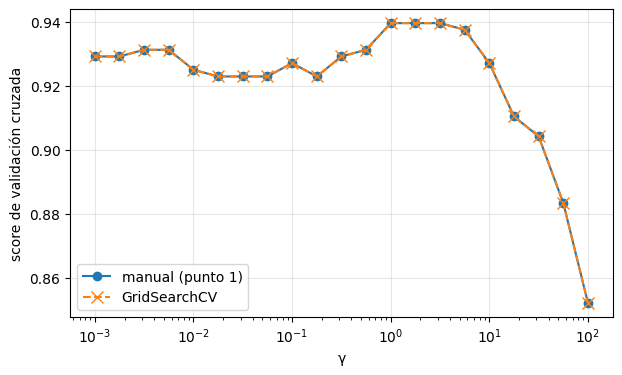

In [10]:
# comprueba la curva de gamma de 1. con GridSearchCV

gs = GridSearchCV(SVC(), {"gamma": gammas}, cv=kf, return_train_score=True).fit(X_cv, y_cv)

print(f"GridSearchCV: mejor gamma = {gs.best_params_['gamma']:.3f}, score CV = {gs.best_score_:.3f}")
print(f"Manual:  mejor gamma = {g_best:.3f}, score CV = {score_val.max():.3f}")
print("Maxima diferencia entre ambas curvas:", np.abs(gs.cv_results_['mean_test_score'] - score_val).max())

plt.figure(figsize=(7, 4))
plt.semilogx(gammas, score_val, "o-", label="manual (punto 1)")
plt.semilogx(gammas, gs.cv_results_["mean_test_score"], "x--", ms=9, label="GridSearchCV")
plt.xlabel("γ"); plt.ylabel("score de validación cruzada"); plt.legend(); plt.show()

Modelo fijo: SVC(gamma = 1.0 )

Overfitting:
train = 0.912
test = 0.677
brecha = 0.236

Underfitting:
train = 0.557
test = 0.533

Control (gamma=100):
train = 1.000
test = 0.983


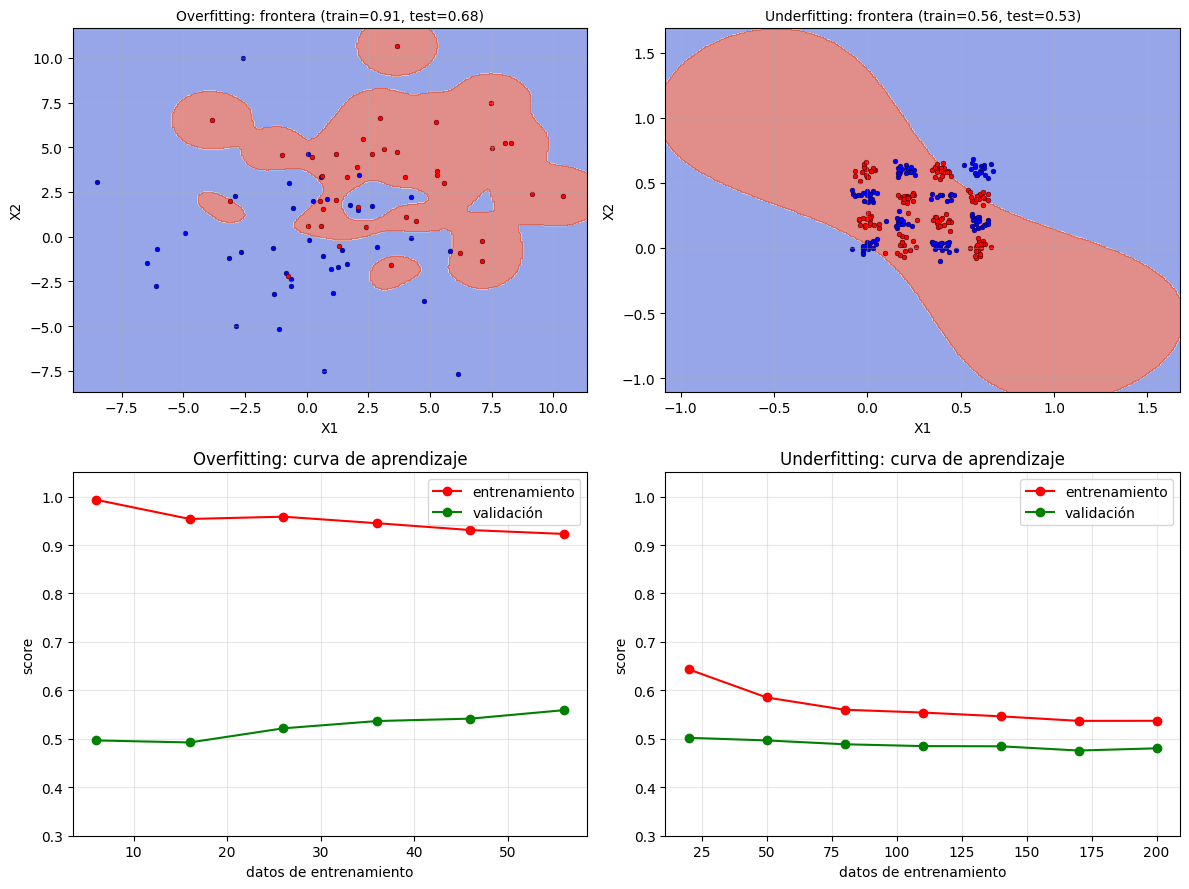

In [18]:
# 3. overfitting y underfitting con el modelo SVC
modelo = SVC(gamma=g_best)
print("Modelo fijo: SVC(gamma =", round(g_best, 3), ")")

# overfitting
I2 = np.eye(2)
X_o, y_o = generar([0, 0], 9 * I2, [3, 3], 9 * I2, n0=40, n1=40, seed=3)
# conjunto de test grande e independiente para medir bien la generalizacion
X_o_test, y_o_test = generar([0, 0], 9 * I2, [3, 3], 9 * I2, n0=2000, n1=2000, seed=99)

m_o = SVC(gamma=g_best).fit(X_o, y_o)
tr_o, te_o = m_o.score(X_o, y_o), m_o.score(X_o_test, y_o_test)
print(f"\nOverfitting:")
print(f"train = {tr_o:.3f}")
print(f"test = {te_o:.3f}")
print(f"brecha = {tr_o - te_o:.3f}")

# underfitting
rng = np.random.default_rng(0)
X_u, y_u = [], []
for i in range(4):
    for j in range(4):
        X_u.append(rng.multivariate_normal([0.2 * i, 0.2 * j], 0.035**2 * np.eye(2), 25))
        y_u += [(i + j) % 2] * 25
X_u, y_u = np.vstack(X_u), np.array(y_u)
Xu_tr, Xu_te, yu_tr, yu_te = train_test_split(X_u, y_u, test_size=0.3, stratify=y_u, random_state=1)

m_u = SVC(gamma=g_best).fit(Xu_tr, yu_tr)
tr_u, te_u = m_u.score(Xu_tr, yu_tr), m_u.score(Xu_te, yu_te)
print(f"\nUnderfitting:")
print(f"train = {tr_u:.3f}")
print(f"test = {te_u:.3f}")

# control con el mismo dataset con un gamma mucho mayor
m_u2 = SVC(gamma=100).fit(Xu_tr, yu_tr)
print(f"\nControl (gamma=100):")
print(f"train = {m_u2.score(Xu_tr, yu_tr):.3f}")
print(f"test = {m_u2.score(Xu_te, yu_te):.3f}")


fig, ax = plt.subplots(2, 2, figsize=(12, 9))
frontera(ax[0, 0], m_o, X_o, y_o, f"Overfitting: frontera (train={tr_o:.2f}, test={te_o:.2f})")
frontera(ax[0, 1], m_u, Xu_tr, yu_tr, f"Underfitting: frontera (train={tr_u:.2f}, test={te_u:.2f})")

# curvas de aprendizaje de cada caso
cv_o = ShuffleSplit(n_splits=50, test_size=0.3, random_state=0)
tam_o = np.arange(6, 57, 10)
tr, va = curva_manual(modelo, X_o, y_o, tam_o, cv_o)
ax[1, 0].plot(tam_o, tr.mean(1), "o-", c="r", label="entrenamiento")
ax[1, 0].plot(tam_o, va.mean(1), "o-", c="g", label="validación")
ax[1, 0].set_title("Overfitting: curva de aprendizaje")

cv_u = ShuffleSplit(n_splits=30, test_size=0.2, random_state=0)
tam_u = np.arange(20, 211, 30)
tr, va = curva_manual(modelo, X_u, y_u, tam_u, cv_u)
ax[1, 1].plot(tam_u, tr.mean(1), "o-", c="r", label="entrenamiento")
ax[1, 1].plot(tam_u, va.mean(1), "o-", c="g", label="validación")
ax[1, 1].set_title("Underfitting: curva de aprendizaje")
for a in ax[1]:
    a.set_xlabel("datos de entrenamiento"); a.set_ylabel("score"); a.set_ylim(0.3, 1.05); a.legend()
plt.tight_layout(); plt.show()
